# LLMOptiFit — Prompt Classification & Model Router Pipeline

**Complete EDA → Feature Engineering → Multi-Method Classification**

This notebook builds a production-grade **prompt router** by classifying every arena prompt across **4 dimensions**:

| # | Dimension | Approach | Output |
|---|-----------|----------|--------|
| 1 | **Topic Discovery** | TF-IDF + KMeans vs Agglomerative (Unsupervised) | Cluster ID + Keywords |
| 2 | **Task Type** | TF-IDF + LogReg vs Linear SVM vs Random Forest | 8-class label |
| 3 | **Complexity & Tier** | Engineered features + LogReg vs RF vs Gradient Boosting | `nano` / `super` / `ultra` |
| 4 | **Prompt Specificity** *(New)* | Composite scoring from structural & rubric signals | `vague` → `highly_specific` |

Each classification pillar tests **multiple methods**, compares pros & cons, and selects the **best performer**.

---

## 1 · Setup & Data Loading

In [1]:
import sys, re, time, warnings, textwrap
from pathlib import Path
from dataclasses import asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({
    "figure.facecolor": "#fafafa",
    "axes.facecolor":   "#fafafa",
    "axes.grid":        True,
    "grid.alpha":       0.25,
    "font.size":        11,
})
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project Root:", PROJECT_ROOT)

Project Root: /Users/ankitabhanushali/LLMOptiFit


In [2]:
df = pd.read_parquet(PROJECT_ROOT / "data/arena/arena_prompts_english.parquet")
df = df.dropna(how="all", axis=1)
print(f"Loaded: {len(df):,} rows × {len(df.columns)} columns")
df.head(3)

Loaded: 23,613 rows × 10 columns


,prompt_id,prompt,language,model_a,model_b,human_preference,moderation_tag,toxicity_tag,timestamp,modality
0,0,What is the difference between OpenCL and CUDA?,en,chatglm-6b,koala-13b,model_b,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",1.682352e+09,text
1,1,Why did my parent not invite me to their wedding?,en,oasst-pythia-12b,alpaca-13b,tie,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",1.682352e+09,text
2,2,"Fuji vs. Nikon, which is better?",en,koala-13b,oasst-pythia-12b,model_b,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",1.682352e+09,text


## 2 · Exploratory Data Analysis (EDA)

Before building any classifier, we must understand the dataset's shape, distributions,
missing values, and the text characteristics of the `prompt` column.

### 2.1 Dataset Overview — Shape, Types & Missing Values

In [3]:
print(f"Shape: {df.shape}")
print(f"\nColumn Data Types:\n{df.dtypes.to_string()}")
print(f"\nMissing Values (non-zero only):")
nulls = df.isnull().sum()
print(nulls[nulls > 0].to_string() if nulls.any() else "  No missing values in core columns")
print(f"\nDuplicate prompts: {df['prompt'].duplicated().sum():,}")

Shape: (23613, 10)

Column Data Types:
prompt_id             int64
prompt                  str
language                str
model_a                 str
model_b                 str
human_preference        str
moderation_tag       object
toxicity_tag         object
timestamp           float64
modality                str

Missing Values (non-zero only):
  No missing values in core columns

Duplicate prompts: 0


### 2.2 Prompt Text Statistics

In [4]:
df["prompt_len_chars"]   = df["prompt"].str.len()
df["prompt_len_words"]   = df["prompt"].str.split().str.len()
df["prompt_len_sentences"] = df["prompt"].str.count(r"[.!?]+") + 1
df["avg_word_len"]       = df["prompt_len_chars"] / df["prompt_len_words"].clip(lower=1)

stats = df[["prompt_len_chars", "prompt_len_words", "prompt_len_sentences", "avg_word_len"]].describe()
print(stats.round(2).to_string())

       prompt_len_chars  prompt_len_words  prompt_len_sentences  avg_word_len
count          23613.00          23613.00              23613.00      23613.00
mean             175.08             29.15                  3.06          5.64
std              345.64             53.11                  4.77          1.80
min               10.00              1.00                  1.00          2.10
25%               40.00              7.00                  1.00          4.97
50%               66.00             12.00                  2.00          5.47
75%              133.00             24.00                  3.00          6.07
max             2560.00            512.00                112.00        122.00


### 2.3 Prompt Length Distributions

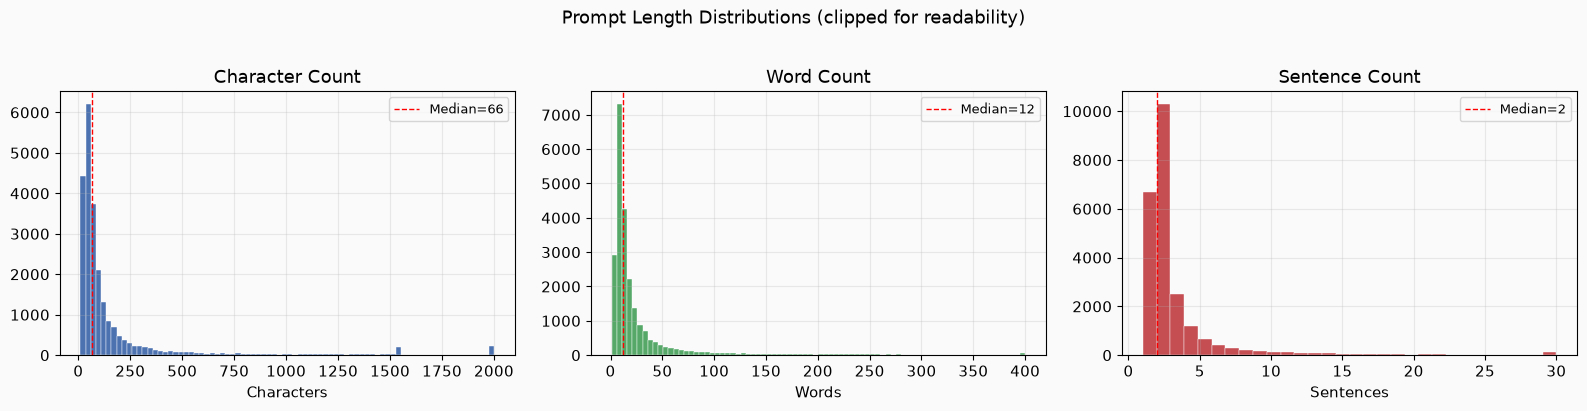


Percentiles (word count):
  P50: 12 words
  P75: 24 words
  P90: 61 words
  P95: 127 words
  P99: 284 words


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df["prompt_len_chars"].clip(upper=2000), bins=80, color="#4C72B0", edgecolor="white", linewidth=0.3)
axes[0].set_title("Character Count"); axes[0].set_xlabel("Characters")
axes[0].axvline(df["prompt_len_chars"].median(), color="red", ls="--", lw=1, label=f'Median={df["prompt_len_chars"].median():.0f}')
axes[0].legend(fontsize=9)

axes[1].hist(df["prompt_len_words"].clip(upper=400), bins=80, color="#55A868", edgecolor="white", linewidth=0.3)
axes[1].set_title("Word Count"); axes[1].set_xlabel("Words")
axes[1].axvline(df["prompt_len_words"].median(), color="red", ls="--", lw=1, label=f'Median={df["prompt_len_words"].median():.0f}')
axes[1].legend(fontsize=9)

axes[2].hist(df["prompt_len_sentences"].clip(upper=30), bins=30, color="#C44E52", edgecolor="white", linewidth=0.3)
axes[2].set_title("Sentence Count"); axes[2].set_xlabel("Sentences")
axes[2].axvline(df["prompt_len_sentences"].median(), color="red", ls="--", lw=1, label=f'Median={df["prompt_len_sentences"].median():.0f}')
axes[2].legend(fontsize=9)

plt.suptitle("Prompt Length Distributions (clipped for readability)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Long-tail analysis
pcts = [50, 75, 90, 95, 99]
print("\nPercentiles (word count):")
for p in pcts:
    v = np.percentile(df["prompt_len_words"].dropna(), p)
    print(f"  P{p}: {v:.0f} words")

### 2.4 Arena Battle Metadata — Preferences & Models

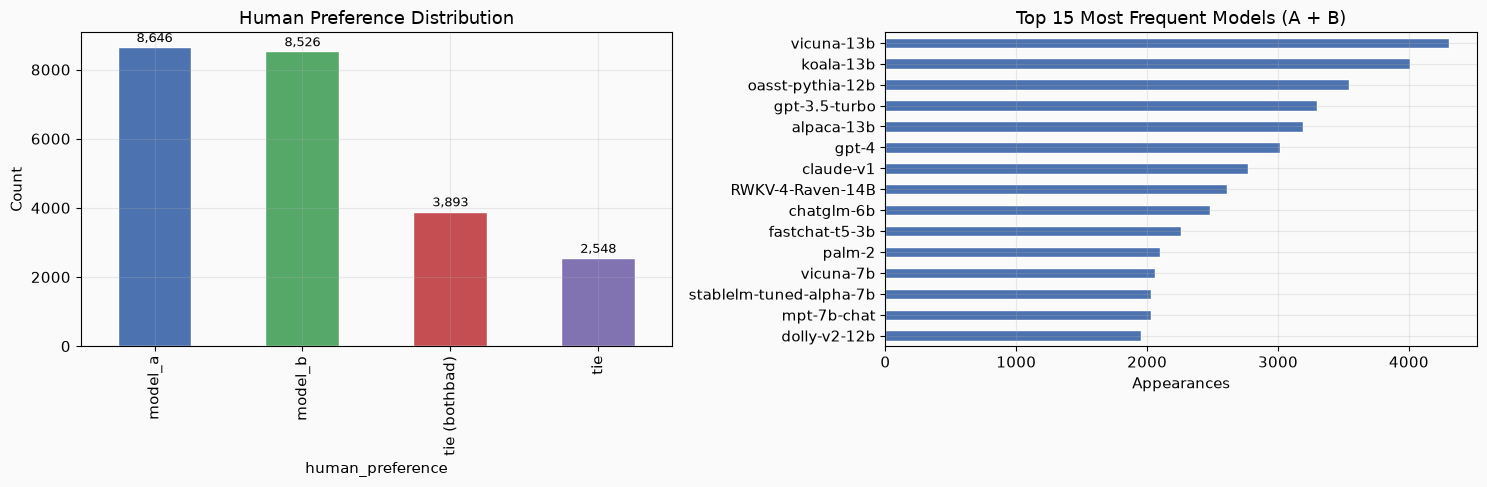

Unique models (model_a): 20
Unique models (model_b): 20


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Human preference
pref = df["human_preference"].value_counts()
colors_pref = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"][:len(pref)]
pref.plot.bar(ax=axes[0], color=colors_pref, edgecolor="white")
axes[0].set_title("Human Preference Distribution")
axes[0].set_ylabel("Count")
for i, (v, c) in enumerate(zip(pref.values, pref.index)):
    axes[0].text(i, v + 150, f"{v:,}", ha="center", fontsize=9)

# Top 15 models (combined A & B)
all_models = pd.concat([df["model_a"], df["model_b"]]).value_counts().head(15)
all_models.plot.barh(ax=axes[1], color="#4C72B0", edgecolor="white")
axes[1].set_title("Top 15 Most Frequent Models (A + B)")
axes[1].set_xlabel("Appearances")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print(f"Unique models (model_a): {df['model_a'].nunique()}")
print(f"Unique models (model_b): {df['model_b'].nunique()}")

### 2.5 Structural Pattern Detection in Prompts

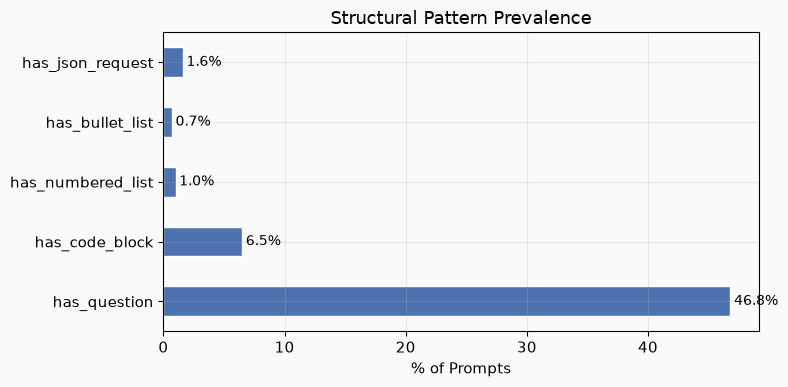


Conditional clauses per prompt — mean: 0.12, max: 9
Constraint keywords per prompt  — mean: 0.13, max: 16


In [7]:
df["has_question"]      = df["prompt"].str.contains(r"\?", na=False).astype(int)
df["has_code_block"]    = df["prompt"].str.contains(
    r"```|\bdef \b|\bclass \b|\bimport \b|\bfunction\b|\bSELECT \b|\bCREATE \b|\bfor \(|\bwhile \(",
    case=False, na=False
).astype(int)
df["has_numbered_list"] = df["prompt"].str.contains(r"(?:^|\n)\s*\d+[\.)\-]", na=False).astype(int)
df["has_bullet_list"]   = df["prompt"].str.contains(r"(?:^|\n)\s*[-*•]\s", na=False).astype(int)
df["n_conditionals"]    = df["prompt"].str.count(
    r"\b(?:if|unless|except|otherwise|when|provided that)\b"
).fillna(0).astype(int)
df["n_constraints"]     = df["prompt"].str.count(
    r"\b(?:must|should|never|always|do not|don't|only if|ensure|make sure)\b"
).fillna(0).astype(int)
df["has_json_request"]  = df["prompt"].str.contains(
    r"\bjson\b|\byaml\b|\bcsv\b|\bschema\b|\bmarkdown\b|\bxml\b", case=False, na=False
).astype(int)

pattern_cols = ["has_question", "has_code_block", "has_numbered_list",
                "has_bullet_list", "has_json_request"]
pattern_pct = (df[pattern_cols].mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 4))
pattern_pct.plot.barh(ax=ax, color="#4C72B0", edgecolor="white")
ax.set_xlabel("% of Prompts")
ax.set_title("Structural Pattern Prevalence")
for i, v in enumerate(pattern_pct.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=10)
plt.tight_layout()
plt.show()

print(f"\nConditional clauses per prompt — mean: {df['n_conditionals'].mean():.2f}, max: {df['n_conditionals'].max()}")
print(f"Constraint keywords per prompt  — mean: {df['n_constraints'].mean():.2f}, max: {df['n_constraints'].max()}")

## 3 · Feature Engineering

We build two feature sets:
1. **14-parameter rubric features** from the heuristic `PromptFeatureExtractor` — captures reasoning depth,
   domain difficulty, accuracy requirements, tool needs, etc.
2. **Text-structural features** — prompt length metrics, structural patterns (questions, code blocks, lists),
   and constraint density.

These are combined to train the Tier Router (Pillar 3). TF-IDF features are built separately for
Topic Discovery (Pillar 1) and Task Type (Pillar 2).

### 3.1 Extract 14-Parameter Rubric Features + Heuristic Labels

In [8]:
from tools.prompt_classifier import PromptFeatureExtractor, WEIGHTS, TASK_TYPE_LOAD

extractor = PromptFeatureExtractor()

rubric_records = []
n_total = len(df)
t0 = time.time()

for i, prompt in enumerate(df["prompt"].fillna("")):
    if i % 5000 == 0:
        print(f"  Extracting rubric features: {i:,}/{n_total:,} ...")
    scores = extractor.extract(prompt)
    rubric_records.append(asdict(scores))

elapsed = time.time() - t0
rubric_df = pd.DataFrame(rubric_records)
# Rename numeric rubric load to avoid collision with categorical task_type label
rubric_df = rubric_df.rename(columns={"task_type": "task_type_score"})

# Merge rubric features into main DataFrame
df = pd.concat([df.reset_index(drop=True), rubric_df.reset_index(drop=True)], axis=1)
print(f"\nExtracted 14 rubric parameters for {n_total:,} prompts in {elapsed:.1f}s")
print(f"Feature matrix: {df.shape[0]:,} rows × {df.shape[1]} columns")

  Extracting rubric features: 0/23,613 ...
  Extracting rubric features: 5,000/23,613 ...
  Extracting rubric features: 10,000/23,613 ...
  Extracting rubric features: 15,000/23,613 ...
  Extracting rubric features: 20,000/23,613 ...

Extracted 14 rubric parameters for 23,613 prompts in 1.2s
Feature matrix: 23,613 rows × 36 columns


### 3.2 Compute Weighted Complexity Score & Assign Route Tier

In [9]:
RUBRIC_FEATURE_COLS = [c if c != "task_type" else "task_type_score" for c in WEIGHTS.keys()]
weight_values = np.array([WEIGHTS[k] for k in WEIGHTS.keys()])

# Weighted complexity score (the heuristic formula)
df["complexity_score"] = df[RUBRIC_FEATURE_COLS].to_numpy(dtype=float) @ weight_values

# Route tier assignment (using same thresholds as HeuristicRouter)
def assign_tier(row):
    s = row["complexity_score"]
    lat = row["latency_sensitivity"]
    cost = row["cost_sensitivity"]
    rc = row["reasoning_complexity"]
    acc = row["accuracy_requirement"]
    if lat >= 0.7 or cost >= 0.7:
        if s < 0.55:
            return "nano"
    if s >= 0.58 or (rc >= 0.65 and acc >= 0.5):
        return "ultra"
    if s >= 0.32:
        return "super"
    return "nano"

df["route_tier"] = df.apply(assign_tier, axis=1)

print("Route Tier Distribution:")
print(df["route_tier"].value_counts().to_string())
print(f"\nComplexity Score Stats:")
print(df["complexity_score"].describe().round(4).to_string())

Route Tier Distribution:
route_tier
nano     22671
super      912
ultra       30

Complexity Score Stats:
count    23613.0000
mean         0.1688
std          0.0640
min          0.0753
25%          0.1291
50%          0.1371
75%          0.1962
max          0.6314


### 3.3 Rubric Feature Distribution & Correlation Heatmap

In [10]:
# Rubric feature statistics
print("14-Parameter Rubric Feature Summary:\n")
print(df[RUBRIC_FEATURE_COLS].describe().round(3).to_string())

14-Parameter Rubric Feature Summary:

       reasoning_complexity  task_type_score  decision_search_complexity  accuracy_requirement  instruction_complexity  context_requirement  output_complexity  iteration_verification_need  domain_difficulty  tool_requirement  freshness_requirement  ambiguity  latency_sensitivity  cost_sensitivity
count             23613.000        23613.000                   23613.000             23613.000               23613.000            23613.000          23613.000                    23613.000          23613.000         23613.000              23613.000  23613.000            23613.000         23613.000
mean                  0.143            0.535                       0.017                 0.118                   0.028                0.135              0.281                        0.024              0.089             0.024                  0.033      0.330                0.008             0.013
std                   0.118            0.145                       0

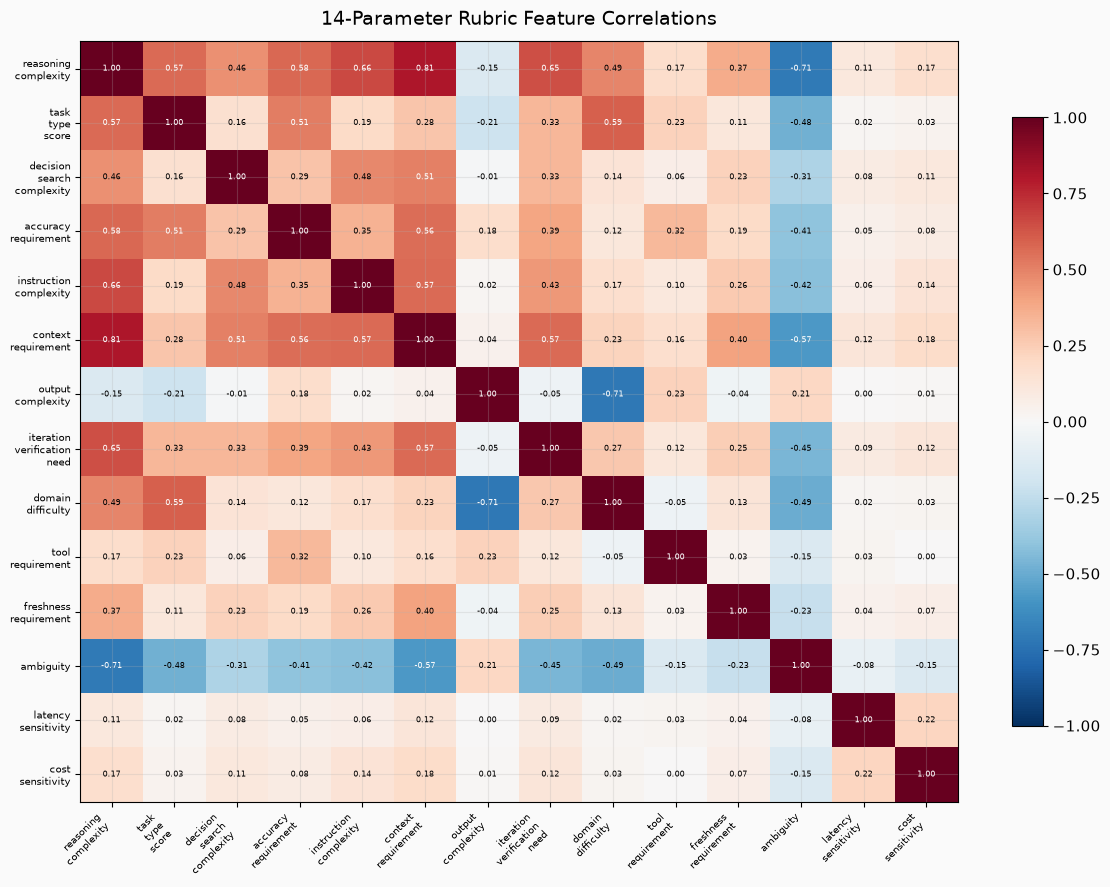

In [11]:
fig, ax = plt.subplots(figsize=(12, 9))
corr = df[RUBRIC_FEATURE_COLS].corr()
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")

short_names = [c.replace("_", "\n") for c in RUBRIC_FEATURE_COLS]
ax.set_xticks(range(len(RUBRIC_FEATURE_COLS)))
ax.set_yticks(range(len(RUBRIC_FEATURE_COLS)))
ax.set_xticklabels(short_names, fontsize=7, rotation=45, ha="right")
ax.set_yticklabels(short_names, fontsize=7)

for i in range(len(RUBRIC_FEATURE_COLS)):
    for j in range(len(RUBRIC_FEATURE_COLS)):
        val = corr.iloc[i, j]
        color = "white" if abs(val) > 0.5 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=5.5, color=color)

plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("14-Parameter Rubric Feature Correlations", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

### 3.4 Build TF-IDF Feature Matrix

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=8000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
)
tfidf_matrix = tfidf.fit_transform(df["prompt"].fillna(""))
print(f"TF-IDF Matrix: {tfidf_matrix.shape[0]:,} docs × {tfidf_matrix.shape[1]:,} features")
print(f"Density: {tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1]) * 100:.2f}%")

TF-IDF Matrix: 23,613 docs × 8,000 features
Density: 0.13%


## 4 · Pillar 1: Topic Discovery (Unsupervised Clustering)

**Goal:** Discover the natural thematic groups in the arena prompts *without* manual labeling.

**Methods tested:**
- **A) TF-IDF + MiniBatch KMeans** — Fast, scalable, stable centroids for keyword extraction.
- **B) TF-IDF + Agglomerative Clustering** — Hierarchical, captures nested topic structure.

**Evaluation:** Silhouette Score (higher = tighter, better-separated clusters).

We test k ∈ {6, 8, 10, 12, 15} and pick the best (method, k) pair.

In [13]:
from sklearn.cluster import MiniBatchKMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD

# Dimensionality reduction for speed and denoising
svd = TruncatedSVD(n_components=50, random_state=42)
tfidf_reduced = svd.fit_transform(tfidf_matrix)
print(f"SVD: {tfidf_matrix.shape[1]:,} features → 50 components")
print(f"Explained variance (50 components): {svd.explained_variance_ratio_.sum():.1%}")

k_range = [6, 8, 10, 12, 15]
SIL_SAMPLE = min(5000, len(df))
sample_idx = np.random.RandomState(42).choice(len(df), size=SIL_SAMPLE, replace=False)
tfidf_sub = tfidf_reduced[sample_idx]

results_km = {}
results_agg = {}

print(f"\n{'k':>3} | {'KMeans Sil':>12} | {'Agglom Sil':>12} | {'KMeans Time':>12} | {'Agglom Time':>12}")
print("-" * 65)

for k in k_range:
    # Method A: KMeans (fit on full dataset)
    t0 = time.time()
    km = MiniBatchKMeans(n_clusters=k, random_state=42, batch_size=1024, n_init=3)
    labels_km = km.fit_predict(tfidf_reduced)
    time_km = time.time() - t0
    sil_km = silhouette_score(tfidf_reduced, labels_km, sample_size=SIL_SAMPLE, random_state=42)
    results_km[k] = {"labels": labels_km, "silhouette": sil_km, "model": km, "time": time_km}

    # Method B: Agglomerative (evaluated on representative sample for O(N²) scalability)
    t0 = time.time()
    agg = AgglomerativeClustering(n_clusters=k)
    labels_agg = agg.fit_predict(tfidf_sub)
    time_agg = time.time() - t0
    sil_agg = silhouette_score(tfidf_sub, labels_agg, random_state=42)
    results_agg[k] = {"silhouette": sil_agg, "time": time_agg}

    print(f"{k:3d} | {sil_km:12.4f} | {sil_agg:12.4f} | {time_km:10.2f}s | {time_agg:10.2f}s")

SVD: 8,000 features → 50 components
Explained variance (50 components): 12.1%

  k |   KMeans Sil |   Agglom Sil |  KMeans Time |  Agglom Time
-----------------------------------------------------------------
  6 |       0.1980 |       0.1710 |       0.06s |       0.30s
  8 |       0.1991 |       0.1889 |       0.03s |       0.28s
 10 |       0.2061 |       0.2037 |       0.01s |       0.28s
 12 |       0.2208 |       0.2189 |       0.04s |       0.28s
 15 |       0.2265 |       0.2068 |       0.05s |       0.28s


### 4.1 Silhouette Score Comparison Plot

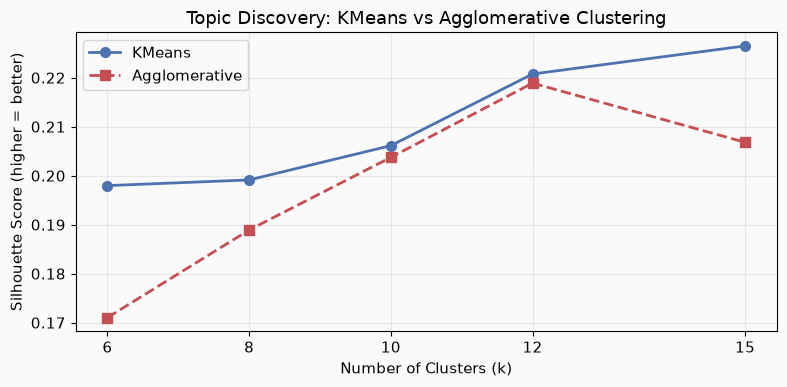

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_range, [results_km[k]["silhouette"] for k in k_range],
        "o-", label="KMeans", color="#4C72B0", linewidth=2, markersize=7)
ax.plot(k_range, [results_agg[k]["silhouette"] for k in k_range],
        "s--", label="Agglomerative", color="#C44E52", linewidth=2, markersize=7)
ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Silhouette Score (higher = better)")
ax.set_title("Topic Discovery: KMeans vs Agglomerative Clustering")
ax.legend(fontsize=11)
ax.set_xticks(k_range)
plt.tight_layout()
plt.show()

### 4.2 Best Clustering Method — Winner & Topic Keywords

In [15]:
# Pick best (method, k) by silhouette
best_k_km  = max(results_km,  key=lambda k: results_km[k]["silhouette"])
best_k_agg = max(results_agg, key=lambda k: results_agg[k]["silhouette"])
sil_km_best  = results_km[best_k_km]["silhouette"]
sil_agg_best = results_agg[best_k_agg]["silhouette"]

print("=" * 70)
print("TOPIC DISCOVERY — METHOD COMPARISON")
print("=" * 70)
print(f"  KMeans       best k={best_k_km:2d}  silhouette={sil_km_best:.4f}  time={results_km[best_k_km]['time']:.2f}s")
print(f"  Agglomerative best k={best_k_agg:2d}  silhouette={sil_agg_best:.4f}  time={results_agg[best_k_agg]['time']:.2f}s")
print()

if sil_km_best >= sil_agg_best:
    winner_method = "KMeans"
    winner_k = best_k_km
    df["topic_cluster"] = results_km[best_k_km]["labels"]
else:
    winner_method = "Agglomerative"
    winner_k = best_k_agg
    agg_winner = AgglomerativeClustering(n_clusters=winner_k)
    df["topic_cluster"] = agg_winner.fit_predict(tfidf_reduced)

winner_sil = max(sil_km_best, sil_agg_best)
print(f"  ★ WINNER: {winner_method} (k={winner_k}, silhouette={winner_sil:.4f})")

print(f"\n  Pros of {winner_method}:")
if winner_method == "KMeans":
    print("    • Much faster (MiniBatch scales to millions)")
    print("    • Produces centroids for easy keyword extraction")
    print("    • Simple to deploy in production (predict new prompts via nearest centroid)")
else:
    print("    • Better captures hierarchical topic relationships")
    print("    • No need to specify batch size or n_init")
print(f"\n  Cons of {winner_method}:")
if winner_method == "KMeans":
    print("    • Assumes spherical clusters (may miss elongated topic regions)")
    print("    • Sensitive to initialization (mitigated by n_init>1)")
else:
    print("    • Much slower (O(n²) memory), doesn't scale beyond ~50k")
    print("    • No centroids — harder to extract keywords and assign new prompts")

# Extract top keywords per cluster
feature_names = np.array(tfidf.get_feature_names_out())
topic_labels = {}
print(f"\n{'='*70}")
print(f"DISCOVERED TOPICS ({winner_method}, k={winner_k})")
print(f"{'='*70}")

for cid in range(winner_k):
    mask = (df["topic_cluster"] == cid).to_numpy()
    count = mask.sum()
    cluster_tfidf_mean = np.asarray(tfidf_matrix[mask].mean(axis=0)).ravel()
    top_idx = np.argsort(cluster_tfidf_mean)[::-1][:8]
    keywords = feature_names[top_idx].tolist()
    topic_labels[cid] = keywords[:3]
    print(f"  Topic {cid:2d} ({count:>5,} prompts): {', '.join(keywords)}")

df["topic_name"] = df["topic_cluster"].map(lambda c: f"T{c}: {', '.join(topic_labels[c])}")

TOPIC DISCOVERY — METHOD COMPARISON
  KMeans       best k=15  silhouette=0.2265  time=0.05s
  Agglomerative best k=12  silhouette=0.2189  time=0.28s

  ★ WINNER: KMeans (k=15, silhouette=0.2265)

  Pros of KMeans:
    • Much faster (MiniBatch scales to millions)
    • Produces centroids for easy keyword extraction
    • Simple to deploy in production (predict new prompts via nearest centroid)

  Cons of KMeans:
    • Assumes spherical clusters (may miss elongated topic regions)
    • Sensitive to initialization (mitigated by n_init>1)

DISCOVERED TOPICS (KMeans, k=15)
  Topic  0 (  545 prompts): best, best way, way, square root, root, square, world, tell best
  Topic  1 (  742 prompts): explain, old, like, works, year old, quantum, explain quantum, simple
  Topic  2 (  633 prompts): tell, joke, tell joke, know, funny, fact, tell history, history
  Topic  3 (1,457 prompts): use, create, model, language, large, models, large language, language model
  Topic  4 (  492 prompts): make, mone

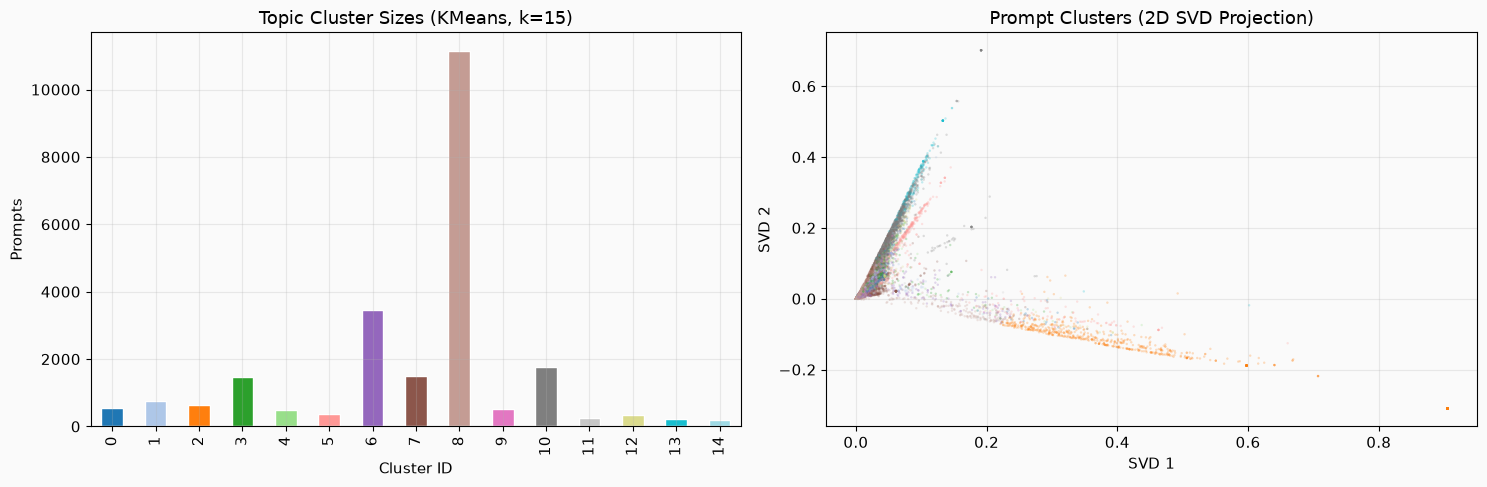

In [16]:
# Visualize clusters
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Cluster size bar chart
cluster_counts = df["topic_cluster"].value_counts().sort_index()
colors = plt.cm.tab20(np.linspace(0, 1, winner_k))
cluster_counts.plot.bar(ax=axes[0], color=colors, edgecolor="white")
axes[0].set_title(f"Topic Cluster Sizes ({winner_method}, k={winner_k})")
axes[0].set_xlabel("Cluster ID"); axes[0].set_ylabel("Prompts")

# 2D SVD scatter
svd2 = TruncatedSVD(n_components=2, random_state=42)
coords = svd2.fit_transform(tfidf_matrix)
scatter = axes[1].scatter(coords[:, 0], coords[:, 1], c=df["topic_cluster"],
                          cmap="tab20", alpha=0.25, s=3, edgecolors="none")
axes[1].set_title("Prompt Clusters (2D SVD Projection)")
axes[1].set_xlabel("SVD 1"); axes[1].set_ylabel("SVD 2")

plt.tight_layout()
plt.show()

## 5 · Pillar 2: Task Type Classification (Supervised)

**Goal:** Classify each prompt into one of 8 canonical task types:
`classification`, `extraction`, `generation`, `coding`, `analysis`, `planning`, `research`, `mathematical_reasoning`

**Labels source:** The heuristic `PromptFeatureExtractor._predict_task_type()` provides initial labels
via keyword matching. ML models trained on TF-IDF features will learn richer lexical patterns and
generalize better than rigid keyword rules.

**Methods tested:**
- **A) Logistic Regression** (multinomial, L2, saga solver)
- **B) Linear SVM** (SGDClassifier, hinge loss, balanced weights)
- **C) Random Forest** (200 trees, balanced weights)

**Evaluation:** Macro-F1 (treats all classes equally, crucial for imbalanced task types).

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

# Label distribution
df["task_type"] = df["predicted_task_type"]
print("Task Type Label Distribution:")
print(df["task_type"].value_counts().to_string())

X_tfidf = tfidf_matrix
y_task = np.array(df["task_type"].to_list())

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_tfidf, y_task, test_size=0.2, random_state=42, stratify=y_task
)
print(f"\nTrain: {X_train_t.shape[0]:,} | Test: {X_test_t.shape[0]:,}")

Task Type Label Distribution:
task_type
generation                16298
analysis                   4053
coding                     1879
planning                    545
mathematical_reasoning      341
classification              257
extraction                  143
research                     97

Train: 18,890 | Test: 4,723


### 5.1 Train & Compare Three Classifiers

In [18]:
task_classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=500, C=1.0, solver="lbfgs", random_state=42
    ),
    "Linear SVM (SGD)": SGDClassifier(
        loss="hinge", max_iter=1000, random_state=42, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=30, random_state=42, n_jobs=-1,
        class_weight="balanced"
    ),
}

task_results = {}
for name, clf in task_classifiers.items():
    t0 = time.time()
    clf.fit(X_train_t, y_train_t)
    train_time = time.time() - t0

    t0 = time.time()
    y_pred = clf.predict(X_test_t)
    infer_time = time.time() - t0

    macro_f1   = f1_score(y_test_t, y_pred, average="macro")
    weighted_f1 = f1_score(y_test_t, y_pred, average="weighted")

    task_results[name] = {
        "model": clf, "macro_f1": macro_f1, "weighted_f1": weighted_f1,
        "train_time": train_time, "infer_time": infer_time, "y_pred": y_pred,
    }

# Print results
print(f"{'Method':<25} | {'Macro-F1':>9} | {'Wtd-F1':>9} | {'Train':>8} | {'Infer':>8}")
print("-" * 72)
for name, r in task_results.items():
    print(f"{name:<25} | {r['macro_f1']:9.4f} | {r['weighted_f1']:9.4f} | "
          f"{r['train_time']:6.2f}s | {r['infer_time']:6.3f}s")

Method                    |  Macro-F1 |    Wtd-F1 |    Train |    Infer
------------------------------------------------------------------------
Logistic Regression       |    0.4526 |    0.7858 |   0.37s |  0.000s
Linear SVM (SGD)          |    0.6650 |    0.8193 |   0.06s |  0.000s
Random Forest             |    0.7087 |    0.7652 |   0.17s |  0.015s


### 5.2 Best Task Type Classifier — Detailed Report

In [19]:
best_task_name = max(task_results, key=lambda n: task_results[n]["macro_f1"])
best_task = task_results[best_task_name]

print(f"★ BEST TASK TYPE CLASSIFIER: {best_task_name}")
print(f"  Macro-F1 = {best_task['macro_f1']:.4f}")
print("=" * 70)
print(classification_report(y_test_t, best_task["y_pred"]))

# Method comparison summary
print("\n" + "=" * 70)
print("TASK TYPE — METHOD PROS & CONS")
print("=" * 70)

for name, r in task_results.items():
    tag = " ★ WINNER" if name == best_task_name else ""
    print(f"\n{name}{tag}  (Macro-F1={r['macro_f1']:.4f})")
    if "Logistic" in name:
        print("  Pros: Fast training & inference, interpretable coefficients,")
        print("        strong on sparse high-dim TF-IDF, well-calibrated probabilities")
        print("  Cons: Assumes linear class boundaries, may underfit complex patterns")
    elif "SVM" in name:
        print("  Pros: Max-margin separation excels on high-dim sparse data,")
        print("        balanced class weighting helps rare classes")
        print("  Cons: No probability output (needs calibration), slower on large datasets")
    elif "Random Forest" in name:
        print("  Pros: Captures non-linear interactions, robust to outliers,")
        print("        feature importance for explainability")
        print("  Cons: Slow on sparse TF-IDF matrices, needs more memory,")
        print("        can overfit on high-cardinality features")

★ BEST TASK TYPE CLASSIFIER: Random Forest
  Macro-F1 = 0.7087
                        precision    recall  f1-score   support

              analysis       0.45      0.68      0.54       811
        classification       0.51      0.51      0.51        51
                coding       0.72      0.88      0.79       376
            extraction       0.84      0.72      0.78        29
            generation       0.91      0.75      0.82      3260
mathematical_reasoning       0.72      0.90      0.80        68
              planning       0.59      0.83      0.69       109
              research       0.63      0.89      0.74        19

              accuracy                           0.75      4723
             macro avg       0.67      0.77      0.71      4723
          weighted avg       0.80      0.75      0.77      4723


TASK TYPE — METHOD PROS & CONS

Logistic Regression  (Macro-F1=0.4526)
  Pros: Fast training & inference, interpretable coefficients,
        strong on sparse high-d

## 6 · Pillar 3: Complexity & Model Tier Routing (Supervised)

**Goal:** Route each prompt to the right LLM tier — `nano`, `super`, or `ultra` — balancing
quality against cost. Misrouting a hard prompt to nano wastes user time; misrouting an easy
prompt to ultra wastes money.

**Features:** We combine 14 rubric dimensions with 11 structural text features (25 total).
This tests whether ML can learn non-linear interactions that the simple weighted-sum formula misses.

**Methods tested:**
- **A) Logistic Regression** — Fast linear baseline
- **B) Random Forest** — Non-linear ensemble, feature importance
- **C) Gradient Boosting** — Sequentially-correcting ensemble, often strongest on tabular data

**Evaluation:** Macro-F1 + Confusion Matrix (critical to understand which tier boundaries blur).

In [20]:
from sklearn.ensemble import GradientBoostingClassifier

STRUCTURAL_COLS = [
    "prompt_len_chars", "prompt_len_words", "prompt_len_sentences", "avg_word_len",
    "has_question", "has_code_block", "has_numbered_list", "has_bullet_list",
    "n_conditionals", "n_constraints", "has_json_request"
]
TIER_FEATURE_COLS = RUBRIC_FEATURE_COLS + STRUCTURAL_COLS

X_tier = df[TIER_FEATURE_COLS].to_numpy(dtype=float)
y_tier = np.array(df["route_tier"].to_list())

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_tier, y_tier, test_size=0.2, random_state=42, stratify=y_tier
)
print(f"Tier Features: {X_tier.shape[1]} dimensions ({len(RUBRIC_FEATURE_COLS)} rubric + {len(STRUCTURAL_COLS)} structural)")
print(f"Train: {X_train_r.shape[0]:,} | Test: {X_test_r.shape[0]:,}")
print(f"\nTier Distribution:")
print(pd.Series(y_tier).value_counts().to_string())

Tier Features: 25 dimensions (14 rubric + 11 structural)
Train: 18,890 | Test: 4,723

Tier Distribution:
nano     22671
super      912
ultra       30


### 6.1 Train & Compare Three Tier Routers

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

tier_classifiers = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=500, C=1.0, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=20, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=60, max_depth=3, learning_rate=0.1, random_state=42
    ),
}

tier_results = {}
for name, clf in tier_classifiers.items():
    t0 = time.time()
    clf.fit(X_train_r, y_train_r)
    train_time = time.time() - t0

    t0 = time.time()
    y_pred = clf.predict(X_test_r)
    infer_time = time.time() - t0

    macro_f1   = f1_score(y_test_r, y_pred, average="macro")
    weighted_f1 = f1_score(y_test_r, y_pred, average="weighted")

    tier_results[name] = {
        "model": clf, "macro_f1": macro_f1, "weighted_f1": weighted_f1,
        "train_time": train_time, "infer_time": infer_time, "y_pred": y_pred,
    }

print(f"{'Method':<25} | {'Macro-F1':>9} | {'Wtd-F1':>9} | {'Train':>8} | {'Infer':>8}")
print("-" * 72)
for name, r in tier_results.items():
    print(f"{name:<25} | {r['macro_f1']:9.4f} | {r['weighted_f1']:9.4f} | "
          f"{r['train_time']:6.2f}s | {r['infer_time']:6.3f}s")

Method                    |  Macro-F1 |    Wtd-F1 |    Train |    Infer
------------------------------------------------------------------------
Logistic Regression       |    0.9231 |    0.9976 |   0.10s |  0.000s
Random Forest             |    0.9786 |    0.9953 |   0.27s |  0.026s
Gradient Boosting         |    0.9816 |    0.9959 |   2.76s |  0.003s


### 6.2 Best Tier Router — Confusion Matrix & Feature Importance

★ BEST TIER ROUTER: Gradient Boosting
  Macro-F1 = 0.9816
              precision    recall  f1-score   support

        nano       1.00      1.00      1.00      4535
       super       0.97      0.93      0.95       182
       ultra       1.00      1.00      1.00         6

    accuracy                           1.00      4723
   macro avg       0.99      0.98      0.98      4723
weighted avg       1.00      1.00      1.00      4723



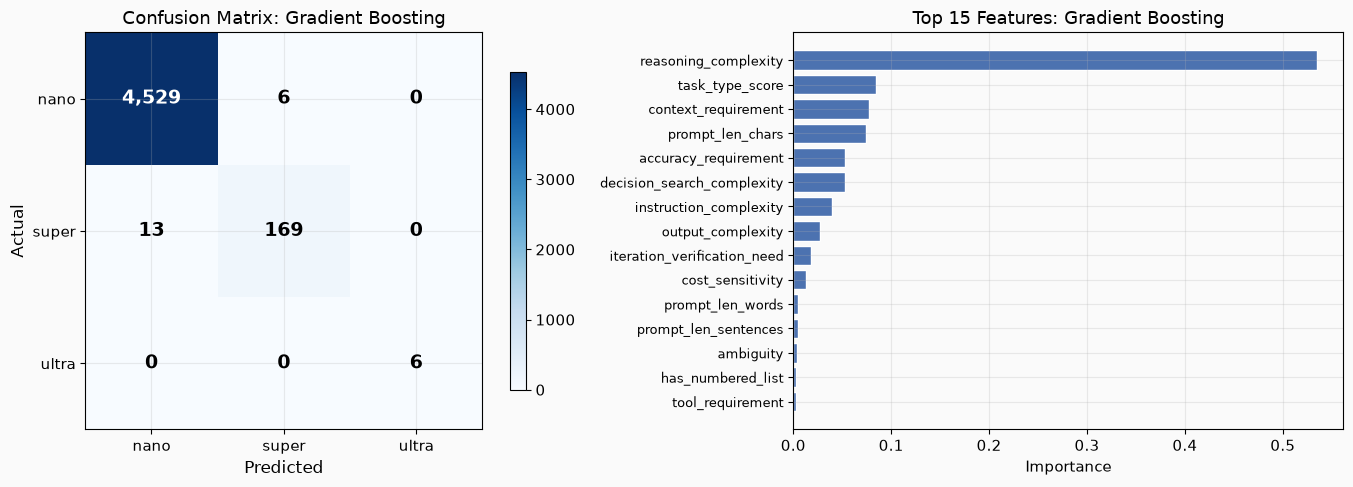

In [22]:
from sklearn.metrics import confusion_matrix

best_tier_name = max(tier_results, key=lambda n: tier_results[n]["macro_f1"])
best_tier = tier_results[best_tier_name]

print(f"★ BEST TIER ROUTER: {best_tier_name}")
print(f"  Macro-F1 = {best_tier['macro_f1']:.4f}")
print("=" * 70)
print(classification_report(y_test_r, best_tier["y_pred"]))

# Confusion Matrix
tier_labels = ["nano", "super", "ultra"]
cm = confusion_matrix(y_test_r, best_tier["y_pred"], labels=tier_labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix heatmap
im = axes[0].imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        axes[0].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color=color, fontsize=14, fontweight="bold")
axes[0].set_xticks(range(3)); axes[0].set_yticks(range(3))
axes[0].set_xticklabels(tier_labels, fontsize=11); axes[0].set_yticklabels(tier_labels, fontsize=11)
axes[0].set_xlabel("Predicted", fontsize=12); axes[0].set_ylabel("Actual", fontsize=12)
axes[0].set_title(f"Confusion Matrix: {best_tier_name}", fontsize=13)
plt.colorbar(im, ax=axes[0], shrink=0.8)

# Feature importance (if available)
from sklearn.pipeline import Pipeline
raw_model = best_tier["model"]
est = raw_model[-1] if isinstance(raw_model, Pipeline) else raw_model
if hasattr(est, "feature_importances_"):
    importances = est.feature_importances_
    sorted_idx = np.argsort(importances)[::-1][:15]
    axes[1].barh(range(len(sorted_idx)), importances[sorted_idx][::-1], color="#4C72B0", edgecolor="white")
    axes[1].set_yticks(range(len(sorted_idx)))
    axes[1].set_yticklabels([TIER_FEATURE_COLS[i] for i in sorted_idx[::-1]], fontsize=9)
    axes[1].set_xlabel("Importance")
    axes[1].set_title(f"Top 15 Features: {best_tier_name}", fontsize=13)
else:
    # For LogReg, show coefficient magnitudes
    coef_mean = np.abs(est.coef_).mean(axis=0)
    sorted_idx = np.argsort(coef_mean)[::-1][:15]
    axes[1].barh(range(len(sorted_idx)), coef_mean[sorted_idx][::-1], color="#4C72B0", edgecolor="white")
    axes[1].set_yticks(range(len(sorted_idx)))
    axes[1].set_yticklabels([TIER_FEATURE_COLS[i] for i in sorted_idx[::-1]], fontsize=9)
    axes[1].set_xlabel("Mean |Coefficient|")
    axes[1].set_title(f"Top 15 Features: {best_tier_name}", fontsize=13)

plt.tight_layout()
plt.show()

In [23]:
# Method comparison summary
print("=" * 70)
print("TIER ROUTING — METHOD PROS & CONS")
print("=" * 70)

for name, r in tier_results.items():
    tag = " ★ WINNER" if name == best_tier_name else ""
    print(f"\n{name}{tag}  (Macro-F1={r['macro_f1']:.4f})")
    if "Logistic" in name:
        print("  Pros: Fastest inference (<0.001s), interpretable coefficients,")
        print("        well-calibrated confidence scores for routing fallback logic")
        print("  Cons: Assumes linear decision boundaries between tiers")
    elif "Random Forest" in name:
        print("  Pros: Captures non-linear feature interactions (e.g., high reasoning +")
        print("        high accuracy → ultra), built-in feature importance, robust")
        print("  Cons: Higher memory, slower training, slight overfitting risk")
    elif "Gradient Boosting" in name:
        print("  Pros: Sequential error correction often yields best tabular accuracy,")
        print("        handles mixed feature scales naturally, good generalization")
        print("  Cons: Slowest training (no parallelism across trees),")
        print("        harder to tune (learning_rate × n_estimators × depth)")

TIER ROUTING — METHOD PROS & CONS

Logistic Regression  (Macro-F1=0.9231)
  Pros: Fastest inference (<0.001s), interpretable coefficients,
        well-calibrated confidence scores for routing fallback logic
  Cons: Assumes linear decision boundaries between tiers

Random Forest  (Macro-F1=0.9786)
  Pros: Captures non-linear feature interactions (e.g., high reasoning +
        high accuracy → ultra), built-in feature importance, robust
  Cons: Higher memory, slower training, slight overfitting risk

Gradient Boosting ★ WINNER  (Macro-F1=0.9816)
  Pros: Sequential error correction often yields best tabular accuracy,
        handles mixed feature scales naturally, good generalization
  Cons: Slowest training (no parallelism across trees),
        harder to tune (learning_rate × n_estimators × depth)


## 7 · Pillar 4: Prompt Specificity — *New Category*

**Why this matters for a model router:**

A vague prompt like *"help me with this"* needs a more capable model to disambiguate intent,
while a precise prompt like *"Extract the ticker symbols from this text as a JSON array"* can
be handled cheaply by a smaller model because the task is crystal clear.

**Specificity is orthogonal to complexity** — a simple but vague prompt (specificity=low, complexity=low)
should be routed differently from a simple but specific prompt.

**Scoring formula (0–1):**
| Signal | Weight | Rationale |
|--------|--------|-----------|
| Word count (capped at 60) | 20% | Longer prompts tend to be more specific |
| Constraint keyword density | 20% | "must", "should", "never" = explicit constraints |
| Instruction complexity (rubric) | 20% | Captures conditional logic and rule density |
| Output format request | 15% | JSON/YAML/table = very specific output expectation |
| Has structured list | 10% | Numbered steps or bullets = organized requirements |
| 1 − Ambiguity (rubric) | 15% | Inverse of detected vagueness cues |

**Levels:** `vague` (< 0.20) · `moderate` (0.20–0.40) · `specific` (0.40–0.65) · `highly_specific` (≥ 0.65)

In [24]:
def compute_specificity(row):
    score = 0.0
    score += min(1.0, row["prompt_len_words"] / 60) * 0.20
    score += min(1.0, row["n_constraints"] / 4) * 0.20
    score += row["instruction_complexity"] * 0.20
    score += row["has_json_request"] * 0.15
    score += max(row["has_numbered_list"], row["has_bullet_list"]) * 0.10
    score += (1.0 - row["ambiguity"]) * 0.15
    return round(score, 4)

df["specificity_score"] = df.apply(compute_specificity, axis=1)

def assign_specificity(s):
    if s < 0.20: return "vague"
    if s < 0.40: return "moderate"
    if s < 0.65: return "specific"
    return "highly_specific"

df["specificity_level"] = df["specificity_score"].apply(assign_specificity)

print("Prompt Specificity Distribution:")
print(df["specificity_level"].value_counts().to_string())
print(f"\nSpecificity Score Stats:")
print(df["specificity_score"].describe().round(4).to_string())

Prompt Specificity Distribution:
specificity_level
vague              16590
moderate            5669
specific            1237
highly_specific      117

Specificity Score Stats:
count    23613.0000
mean         0.1809
std          0.1170
min          0.0479
25%          0.0959
50%          0.1495
75%          0.2232
max          1.0000


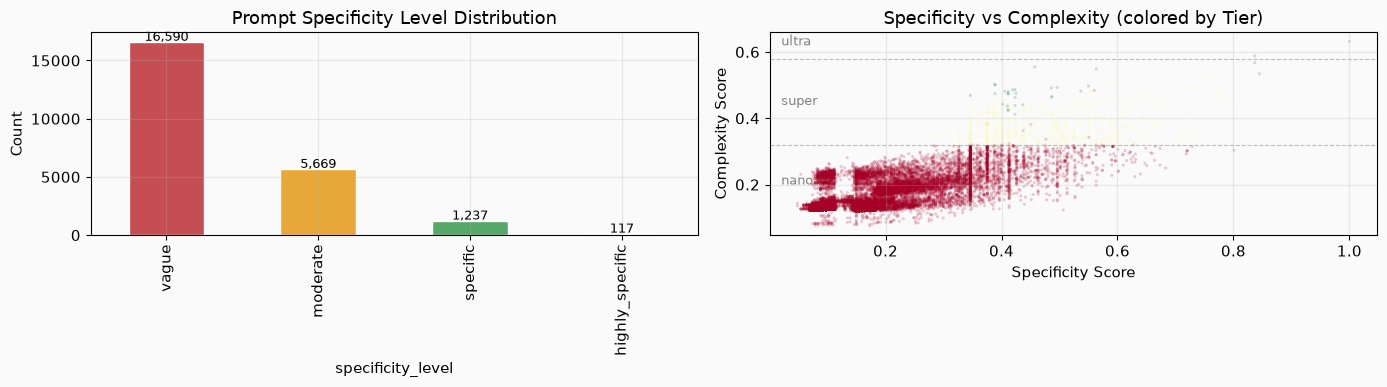

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Distribution
spec_order = ["vague", "moderate", "specific", "highly_specific"]
spec_colors = ["#C44E52", "#E8A838", "#55A868", "#4C72B0"]
spec_counts = df["specificity_level"].value_counts().reindex(spec_order)
spec_counts.plot.bar(ax=axes[0], color=spec_colors, edgecolor="white")
axes[0].set_title("Prompt Specificity Level Distribution")
axes[0].set_ylabel("Count")
for i, v in enumerate(spec_counts.values):
    axes[0].text(i, v + 100, f"{v:,}", ha="center", fontsize=9)

# Specificity vs Complexity scatter
scatter = axes[1].scatter(
    df["specificity_score"], df["complexity_score"],
    c=df["route_tier"].map({"nano": 0, "super": 1, "ultra": 2}),
    cmap="RdYlGn", alpha=0.2, s=5, edgecolors="none"
)
axes[1].set_xlabel("Specificity Score")
axes[1].set_ylabel("Complexity Score")
axes[1].set_title("Specificity vs Complexity (colored by Tier)")
axes[1].axhline(0.32, color="gray", ls="--", lw=0.8, alpha=0.5)
axes[1].axhline(0.58, color="gray", ls="--", lw=0.8, alpha=0.5)
axes[1].text(0.02, 0.20, "nano", fontsize=9, color="gray")
axes[1].text(0.02, 0.44, "super", fontsize=9, color="gray")
axes[1].text(0.02, 0.62, "ultra", fontsize=9, color="gray")

plt.tight_layout()
plt.show()

## 8 · Additional Category Suggestions for the Router

Beyond the 4 pillars above, two more dimensions are highly relevant for a production model router:

### 8.1 Safety / Risk Level
**Why:** Some prompts touch sensitive domains (medical, legal, financial advice, harmful content).
Higher-risk prompts should be routed to models with stronger safety alignment and guardrails,
regardless of complexity.

**Signals:** Presence of medical/legal/financial terminology, moderation tags from the dataset,
toxicity tags, keywords related to violence, self-harm, or PII.

### 8.2 Response Modality
**Why:** As models gain multimodal capabilities, some prompts implicitly request non-text outputs
(code execution, image generation, structured data). The router should detect when a specialized
model or tool-augmented pipeline is needed.

**Signals:** Requests for "draw", "plot", "image", "diagram", "chart", "audio", "table" outputs;
code execution keywords ("run this", "execute", "sandbox").

*These are left as schema-ready placeholders in the exported dataset for future annotation.*

## 9 · Final Summary — Best Methods Across All Pillars

The table below summarizes the winning method for each classification dimension,
along with the key trade-offs that influenced the selection.

In [26]:
summary_data = {
    "Pillar": ["Topic Discovery", "Task Type", "Tier Routing", "Specificity"],
    "Best Method": [
        f"{winner_method} (k={winner_k})",
        best_task_name,
        best_tier_name,
        "Composite Score (rule-based)",
    ],
    "Key Metric": [
        f"Silhouette={winner_sil:.4f}",
        f"Macro-F1={best_task['macro_f1']:.4f}",
        f"Macro-F1={best_tier['macro_f1']:.4f}",
        "N/A (unsupervised)",
    ],
    "Inference Speed": [
        "~1ms (centroid distance)" if winner_method == "KMeans" else "N/A (refit needed)",
        f"{best_task['infer_time']*1000:.0f}ms ({X_test_t.shape[0]:,} prompts)",
        f"{best_tier['infer_time']*1000:.0f}ms ({X_test_r.shape[0]:,} prompts)",
        "<1ms (formula)",
    ],
    "Production Ready?": ["✓", "✓", "✓", "✓"],
}
summary_df = pd.DataFrame(summary_data)
print("=" * 80)
print("FINAL MODEL ROUTER — BEST METHODS SUMMARY")
print("=" * 80)
print(summary_df.to_string(index=False))

FINAL MODEL ROUTER — BEST METHODS SUMMARY
         Pillar                  Best Method         Key Metric          Inference Speed Production Ready?
Topic Discovery                KMeans (k=15)  Silhouette=0.2265 ~1ms (centroid distance)                 ✓
      Task Type                Random Forest    Macro-F1=0.7087     15ms (4,723 prompts)                 ✓
   Tier Routing            Gradient Boosting    Macro-F1=0.9816      3ms (4,723 prompts)                 ✓
    Specificity Composite Score (rule-based) N/A (unsupervised)           <1ms (formula)                 ✓


### 9.1 Export Enriched Dataset

In [27]:
output_cols = [
    "prompt_id", "prompt", "language",
    "model_a", "model_b", "human_preference", "timestamp",
    # Text features
    "prompt_len_words", "prompt_len_chars", "prompt_len_sentences",
    "has_question", "has_code_block", "n_conditionals", "n_constraints",
    # Pillar 1: Topic
    "topic_cluster", "topic_name",
    # Pillar 2: Task Type
    "task_type",
    # Pillar 3: Complexity & Tier
    "complexity_score", "route_tier",
    # Pillar 4: Specificity
    "specificity_score", "specificity_level",
]

# Keep only columns that exist (some metadata cols may be missing)
existing_cols = [c for c in output_cols if c in df.columns]
df_final = df[existing_cols].copy()

output_path = PROJECT_ROOT / "data/arena/arena_prompts_classified.parquet"
df_final.to_parquet(output_path, index=False)
print(f"Saved enriched dataset: {df_final.shape[0]:,} rows × {df_final.shape[1]} columns")
print(f"Path: {output_path}")
df_final.head(8)

Saved enriched dataset: 23,613 rows × 21 columns
Path: /Users/ankitabhanushali/LLMOptiFit/data/arena/arena_prompts_classified.parquet


,prompt_id,prompt,language,model_a,model_b,human_preference,timestamp,prompt_len_words,prompt_len_chars,prompt_len_sentences,...,has_code_block,n_conditionals,n_constraints,topic_cluster,topic_name,task_type,complexity_score,route_tier,specificity_score,specificity_level
0,0,What is the difference between OpenCL and CUDA?,en,chatglm-6b,koala-13b,model_b,1.682352e+09,8,47,2,...,0,0,0,14,"T14: difference, explain difference, explain",generation,0.143035,nano,0.0972,vague
1,1,Why did my parent not invite me to their wedding?,en,oasst-pythia-12b,alpaca-13b,tie,1.682352e+09,10,49,2,...,0,0,0,6,"T6: answer, like, good",generation,0.144208,nano,0.1065,vague
2,2,"Fuji vs. Nikon, which is better?",en,koala-13b,oasst-pythia-12b,model_b,1.682352e+09,6,32,3,...,0,0,0,8,"T8: better, following, sentence",generation,0.152318,nano,0.0879,vague
3,3,How to build an arena for chatbots?,en,vicuna-13b,oasst-pythia-12b,model_b,1.682352e+09,7,35,2,...,0,0,0,8,"T8: better, following, sentence",generation,0.129666,nano,0.0925,vague
4,4,When is it today?,en,vicuna-13b,koala-13b,model_a,1.682352e+09,4,17,2,...,0,0,0,7,"T7: list, know, code",generation,0.156133,nano,0.1106,vague
5,5,Count from 1 to 10 with step = 3,en,vicuna-13b,koala-13b,model_a,1.682352e+09,9,32,1,...,0,0,0,6,"T6: answer, like, good",generation,0.133940,nano,0.1005,vague
6,6,"Emoji for ""sharing"". List 10",en,vicuna-13b,koala-13b,model_a,1.682352e+09,5,28,2,...,0,0,0,7,"T7: list, know, code",generation,0.132422,nano,0.0832,vague
7,7,How to parallelize a neural network?,en,vicuna-13b,dolly-v2-12b,model_a,1.682352e+09,6,36,2,...,0,0,0,8,"T8: better, following, sentence",generation,0.129540,nano,0.0879,vague


### 9.2 Interactive Prompt Router — Test Any Prompt

In [28]:
from tools.prompt_classifier import classify_prompt as _classify_single

def route_prompt(prompt_text):
    """Run the full 4-pillar classification on a single prompt."""
    res = _classify_single(prompt_text)

    words = len(prompt_text.split())
    constraints = len(re.findall(r"\b(?:must|should|never|always|do not|ensure)\b", prompt_text, re.I))
    has_json = int(bool(re.search(r"\bjson\b|\byaml\b|\bcsv\b|\bschema\b", prompt_text, re.I)))
    has_list = int(bool(re.search(r"(?:^|\n)\s*(?:\d+[\.)\-]|[-*•])\s", prompt_text)))
    spec = (
        min(1.0, words / 60) * 0.20
        + min(1.0, constraints / 4) * 0.20
        + res.scores.instruction_complexity * 0.20
        + has_json * 0.15
        + has_list * 0.10
        + (1.0 - res.scores.ambiguity) * 0.15
    )
    spec_label = "vague" if spec < 0.20 else "moderate" if spec < 0.40 else "specific" if spec < 0.65 else "highly_specific"

    return {
        "Task Type": res.scores.predicted_task_type,
        "Complexity Score": round(res.weighted_score, 3),
        "Route Tier": res.route_tier.upper(),
        "Recommended Model": res.recommended_model,
        "Specificity": f"{spec_label} ({spec:.3f})",
        "Top Driver": res.rationale["top_drivers"][0]["parameter"] if res.rationale.get("top_drivers") else "N/A",
    }

# ─── Test prompts spanning the full difficulty spectrum ───
test_prompts = [
    "What is a neural network?",
    "Summarize the key differences between TCP and UDP in a markdown table.",
    "Compare PostgreSQL vs MongoDB for a real-time analytics dashboard with 10M daily events. "
    "Consider query patterns, horizontal scaling, and total cost of ownership.",
    "Design an async Python microservice with Redis pub/sub, circuit breaker retry logic, "
    "structured JSON logging, OpenTelemetry tracing, and Kubernetes health probes. "
    "Include unit tests, a Dockerfile, and verify edge cases. Do not hallucinate.",
]

for p in test_prompts:
    result = route_prompt(p)
    preview = p[:90] + ("..." if len(p) > 90 else "")
    print(f"\nPrompt: \"{preview}\"")
    for k, v in result.items():
        print(f"  {k:20s}: {v}")
print()


Prompt: "What is a neural network?"
  Task Type           : generation
  Complexity Score    : 0.129
  Route Tier          : NANO
  Recommended Model   : nemotron-nano
  Specificity         : vague (0.083)
  Top Driver          : task_type

Prompt: "Summarize the key differences between TCP and UDP in a markdown table."
  Task Type           : generation
  Complexity Score    : 0.166
  Route Tier          : NANO
  Recommended Model   : nemotron-nano
  Specificity         : vague (0.150)
  Top Driver          : task_type

Prompt: "Compare PostgreSQL vs MongoDB for a real-time analytics dashboard with 10M daily events. C..."
  Task Type           : analysis
  Complexity Score    : 0.232
  Route Tier          : SUPER
  Recommended Model   : nemotron-super
  Specificity         : moderate (0.202)
  Top Driver          : task_type

Prompt: "Design an async Python microservice with Redis pub/sub, circuit breaker retry logic, struc..."
  Task Type           : coding
  Complexity Score    : 0